In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from credit_risk import config as C, data as D, features as F, scorecard as S, models as M
from credit_risk import calibration as CAL, business as B, fairness as FAIR, stability as ST
R = lambda s: json.load(open(C.REPORTS / f"metrics_{s}.json"))
def app():
    t = pd.read_parquet(C.ROOT / "data/synthetic/application_train.parquet")  # use data/raw + D.read_table for real data
    return F.engineer_application(D.clean_application(t)), t


# 03 - WoE scorecard
Monotone binning -> WoE/IV -> logistic regression -> points. WoE = ln(good/bad), so higher = safer and coefficients are negative.

In [2]:
df, _ = app(); tr, va, te = D.split_data(df)
enc = F.CategoryEncoder().fit(tr, F.categorical_columns(tr[F.model_feature_columns(tr)]))
tr, va = enc.transform(tr), enc.transform(va)
feats = F.model_feature_columns(tr)
sc, ivt, rep = S.fit_scorecard(tr, tr[C.TARGET], feats)
ivt.head(12)

,feature,iv,strength
0,EXT_SOURCE_WEIGHTED,0.367844,strong
1,EXT_SOURCE_MEAN,0.363121,strong
2,EXT_SOURCE_MIN,0.307355,strong
3,EXT_SOURCE_2,0.303405,strong
4,ANNUITY_INCOME_RATIO,0.255985,medium
5,EXT_SOURCE_PROD,0.246358,medium
6,EXT_SOURCE_3,0.209139,medium
7,CREDIT_INCOME_RATIO,0.167491,medium
8,AMT_ANNUITY,0.107190,medium
9,ANNUITY_CREDIT_RATIO,0.103197,medium


,bin,share,bad_rate,woe
0,"(-inf, 0.215]",0.050000,0.230000,-1.208117
1,"(0.215, 0.2802]",0.050000,0.178333,-0.889861
2,"(0.2802, 0.3237]",0.050000,0.123333,-0.458441
3,"(0.3237, 0.3571]",0.050000,0.116667,-0.395686
4,"(0.3571, 0.4342]",0.149917,0.092829,-0.137009
5,"(0.4342, 0.4784]",0.100000,0.078333,0.046464
6,"(0.4784, 0.5653]",0.199917,0.063360,0.276516
7,"(0.5653, 0.5869]",0.050000,0.056667,0.384624
8,"(0.5869, 0.6409]",0.099917,0.054212,0.438004
9,"(0.6409, 0.6743]",0.050000,0.041667,0.702667


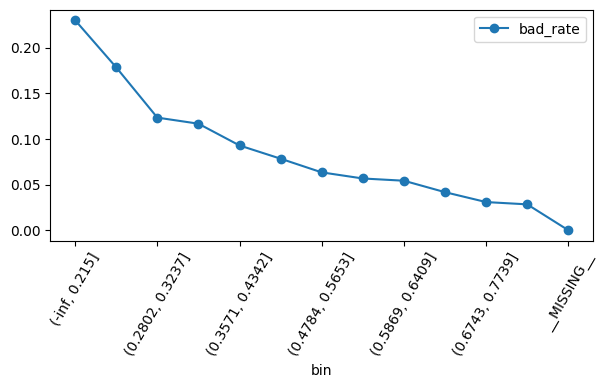

In [3]:
b = sc.binners['EXT_SOURCE_MEAN'].table_; display(b[['bin','share','bad_rate','woe']])
b.plot(x='bin', y='bad_rate', marker='o', figsize=(7,3)); plt.xticks(rotation=60); plt.show()

In [4]:
from sklearn.metrics import roc_auc_score
print('valid AUC', roc_auc_score(va[C.TARGET], sc.predict_pd(va)), '| final vars', rep['n_final'])
sc.points_table_.head(15)

valid AUC 0.7108980235140138 | final vars 12


,variable,bin,share,bad_rate,woe,points
0,EXT_SOURCE_WEIGHTED,"(-inf, 0.2122]",0.050000,0.226667,-1.189256,13.5
1,EXT_SOURCE_WEIGHTED,"(0.2122, 0.2768]",0.050000,0.173333,-0.855497,22.7
2,EXT_SOURCE_WEIGHTED,"(0.2768, 0.321]",0.050000,0.135000,-0.561630,30.9
3,EXT_SOURCE_WEIGHTED,"(0.321, 0.4094]",0.149917,0.101723,-0.238089,39.8
4,EXT_SOURCE_WEIGHTED,"(0.4094, 0.4327]",0.050000,0.088333,-0.088213,44.0
5,EXT_SOURCE_WEIGHTED,"(0.4327, 0.4986]",0.149917,0.075042,0.094415,49.0
6,EXT_SOURCE_WEIGHTED,"(0.4986, 0.5657]",0.150000,0.064444,0.257439,53.5
7,EXT_SOURCE_WEIGHTED,"(0.5657, 0.5893]",0.050000,0.060000,0.324735,55.4
8,EXT_SOURCE_WEIGHTED,"(0.5893, 0.6768]",0.149917,0.045581,0.621933,63.6
9,EXT_SOURCE_WEIGHTED,"(0.6768, 0.72]",0.050000,0.040000,0.744409,67.0
